# TOAST Maploader

Author : Henry Nachman

---

A file to load filterbin maps after they have been made by TOAST

# Imports

In [1]:
import matplotlib.pyplot as plt
import os, sys
import pickle as pkl

abspath = os.path.dirname(os.path.abspath("toast_maploader.ipynb"))
fig_out_path = "/shared_home/henachman/home/SO_PointingReqs/output_analysis"
if abspath not in sys.path:
    sys.path.append(abspath)

from toast_fbmaploader import *

In [2]:
path_to_data = "/shared_home/henachman/data/sim_outputs/Mars/"
SSO = "Mars"
if SSO=="Mars":
    ra = 111.0992
    dec = 25.1832
if SSO=="Jupiter":
    ra = 72.4123427736188
    dec = 22.100098621604207
else:
    ra = 111.0992
    dec = 25.1832
rot = [ra, dec]


maps_dict = {}

In [3]:
print(maps_dict.keys())

dict_keys([])


In [4]:
run_path = {
    "plain" : "Mars_SSO_f090_261020_210359",
    # "offset" : "Mars_SSO_offset_f090_261020_210407",
    # "jitter" : "Mars_SSO_jitter_f090_261020_210415",
    # "hd_plain" : "Mars_SSO_f090_261021_195858",
    # "hd_jitter" : "Mars_SSO_jitter_f090_261021_193527"
    }

for name, path in run_path.items():
    if name not in maps_dict:
        print(f"Adding {name}, {path}")
        I_map, _, _, hits_map = load_h5_map(path, path_to_data=path_to_data)
        try:
            rot_est = get_center(I_map)
        except:
            rot_est = rot
        maps_dict[name] = {"I_map": I_map,
                           "hits_map": hits_map,
                           "rot_est": rot_est,
                           "path":path}

Adding plain, Mars_SSO_f090_261020_210359


In [5]:
# Only run this to read the HD sparse maps
# nside, nest, pix, (I, Q, U) = read_sparse(os.path.join(path_to_data, run_path['hd_jitter'], "filterbin_filtered_map.h5"))
# np.savez_compressed("hd_jitter_sparse.npz", nside=nside, nest=nest, pix=pix,
#                     I=I.astype(np.float32), Q=Q.astype(np.float32), U=U.astype(np.float32))

In [6]:
with np.load("hd_jitter_sparse.npz") as data:
    hd_jitter = {key: data[key] for key in data.files}
with np.load("hd_plain_sparse.npz") as data:
    hd_plain = {key: data[key] for key in data.files}

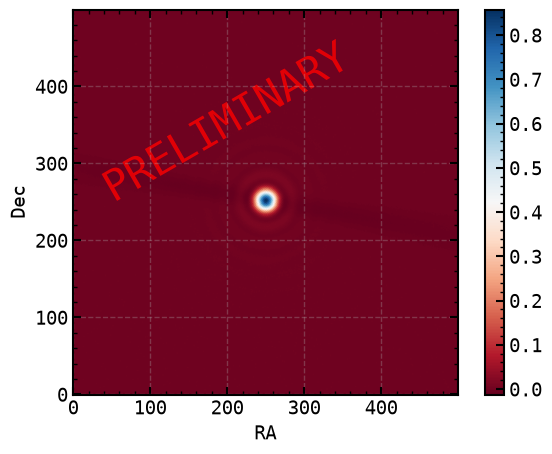

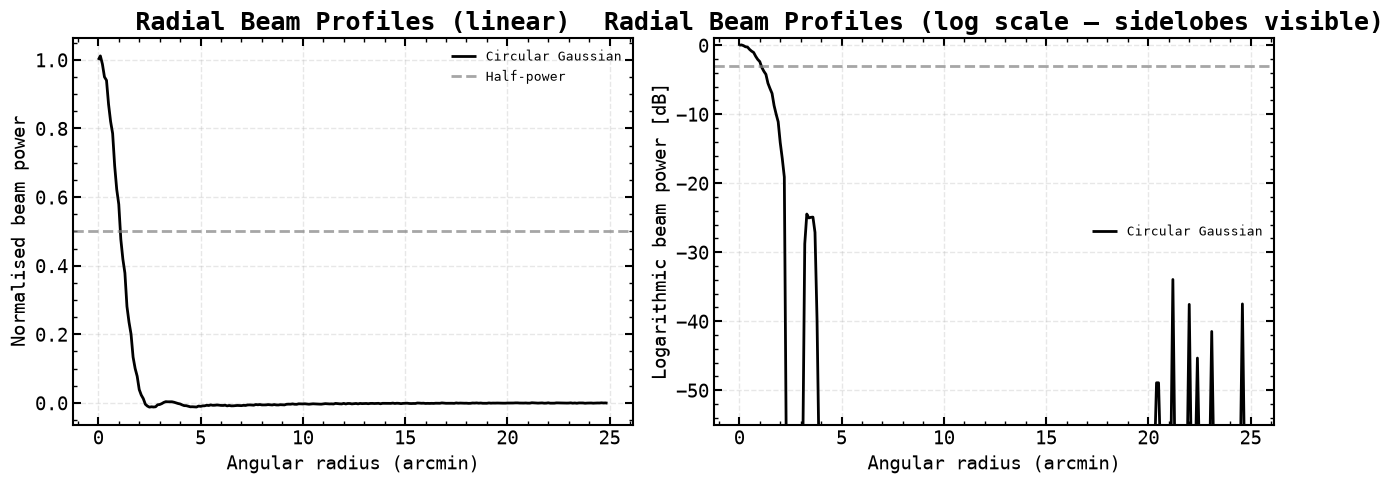

In [7]:
map_name = "hd_plain"
img = sparse_gnomview(
    hd_plain["nside"], 
    hd_plain["nest"], 
    hd_plain["pix"], 
    hd_plain["I"], 
    maps_dict['plain']['rot_est'], 
    xsize=500, 
    reso=0.1,
    cmap="RdBu",
    )

maps_dict[map_name] = {
    "I_map" : img,
    "rot_est" : maps_dict['plain']['rot_est'],
    "path" : "/shared_home/henachman/data/sim_outputs/Mars/HD_Mars_f090"
}
    # Add a centered text watermark
plt.text(200, 350, 'PRELIMINARY',
        fontsize=30, 
        color='red', 
        alpha=0.8,             # Transparency setting
        ha='center', 
        va='center', 
        rotation=30, 
        zorder=0)              # Places text behind data plots

plt.xlabel("RA")
plt.ylabel("Dec")
plt.savefig(os.path.join(path_to_data, maps_dict[map_name]["path"], "filterbin_map.png"), dpi=300)
plt.show()

r_amin, profile = get_radial_profile(img, 500, 0.1, show=True)
plt.savefig(os.path.join(path_to_data, maps_dict[map_name]["path"], "radial_profile.png"), dpi=300)
plt.show()

maps_dict[map_name]["profile"] = [r_amin, profile]

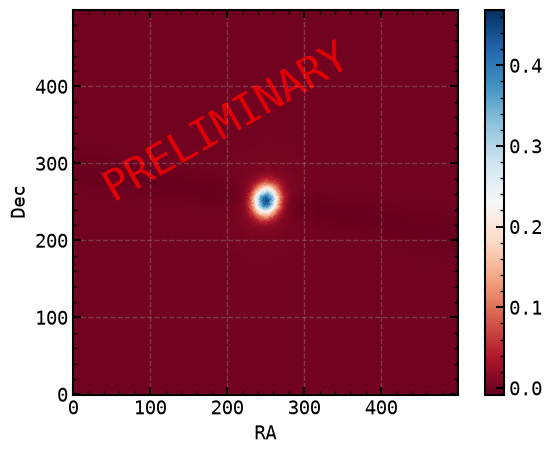

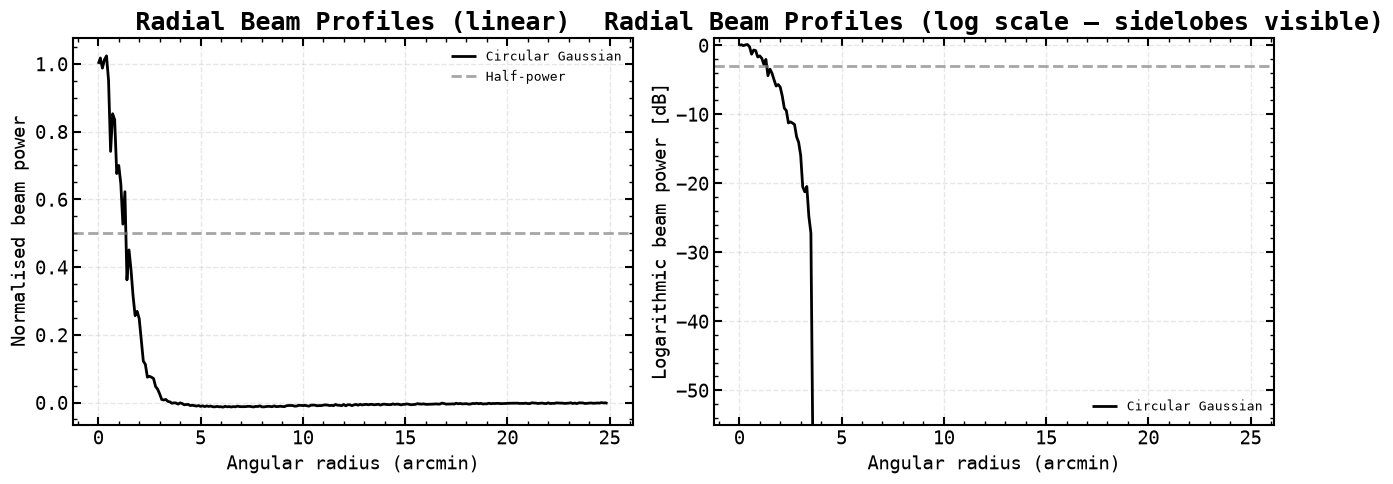

In [8]:
map_name = "hd_jitter"
img = sparse_gnomview(
    hd_jitter["nside"], 
    hd_jitter["nest"], 
    hd_jitter["pix"], 
    hd_jitter["I"], 
    maps_dict['plain']['rot_est'], 
    xsize=500, 
    reso=0.1,
    cmap="RdBu",
    )

maps_dict[map_name] = {
    "I_map" : img,
    "rot_est" : maps_dict['plain']['rot_est'],
    "path" : "/shared_home/henachman/data/sim_outputs/Mars/HD_Mars_jitter_f090"
}

    # Add a centered text watermark
plt.text(200, 350, 'PRELIMINARY',
        fontsize=30, 
        color='red', 
        alpha=0.8,             # Transparency setting
        ha='center', 
        va='center', 
        rotation=30, 
        zorder=0)  

plt.xlabel("RA")
plt.ylabel("Dec")
plt.savefig(os.path.join(path_to_data, maps_dict[map_name]["path"], "filterbin_map.png"), dpi=300)
plt.show()

r_amin, profile = get_radial_profile(img, 500, 0.1, show=True)
plt.savefig(os.path.join(path_to_data, maps_dict[map_name]["path"], "radial_profile.png"), dpi=300)
plt.show()


maps_dict[map_name]["profile"] = [r_amin, profile]

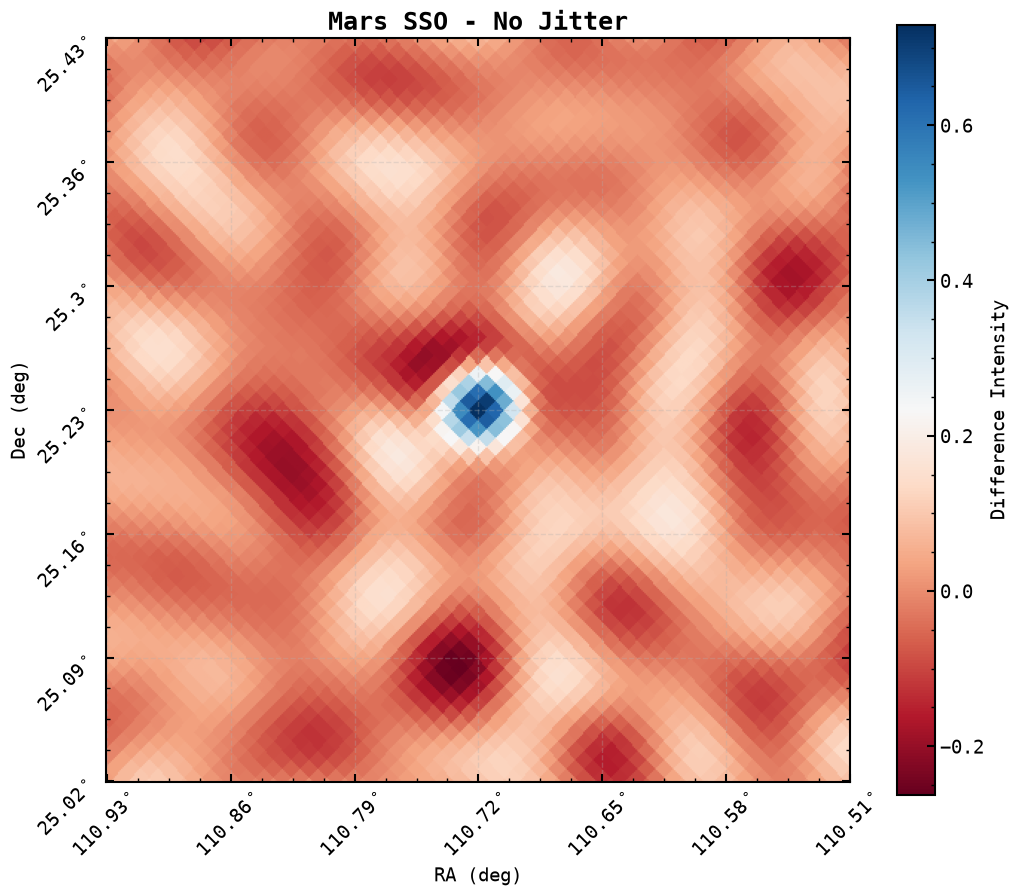

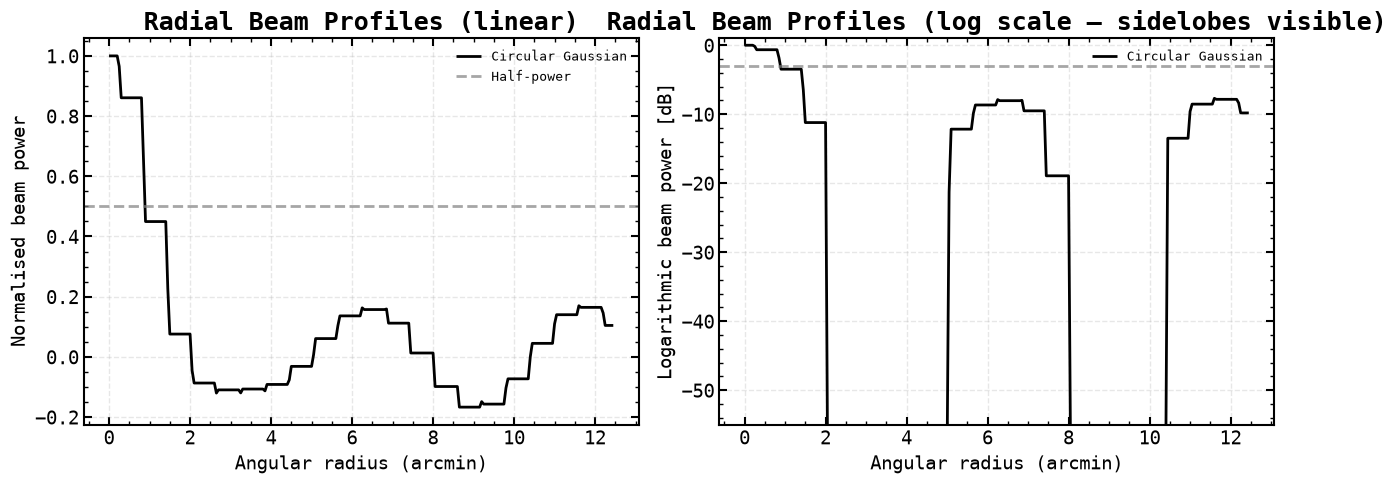

In [9]:
N = 500 # Num pix
pix_size = 0.05 # arcmin per pix

for map_name in ["plain"]: #maps_dict.keys():
    proj_map, _ = single_plot(maps_dict[map_name]["I_map"],
            rot=maps_dict[map_name]["rot_est"],
            xsize=N,
            reso=pix_size,
            cmap='RdBu',
            show=False)
    # print(centroid_center(maps_dict[map_name]["map"], rot))
    plt.title("Mars SSO - No Jitter")
    plt.savefig(os.path.join(path_to_data, maps_dict[map_name]["path"], "filterbin_map.png"), dpi=300)

    r_amin, profile = get_radial_profile(proj_map, N, pix_size, show=True)
    maps_dict[map_name]["profile"] = [r_amin, profile]

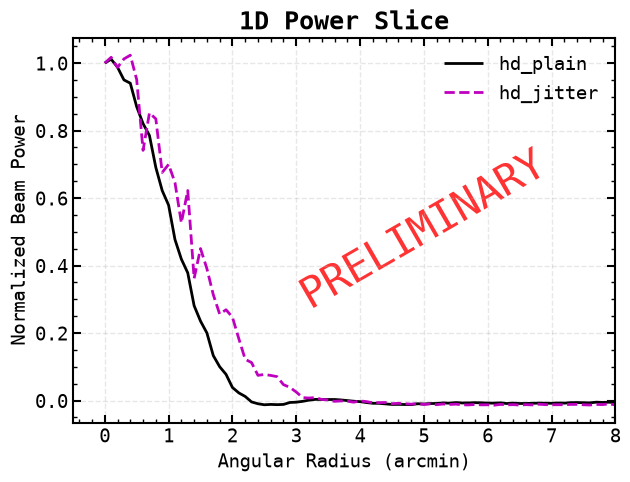

In [10]:
for map_name in ["hd_plain", "hd_jitter"]: #maps_dict.keys():
    x, y = maps_dict[map_name]["profile"]
    plt.plot(x, y, label=f"{map_name}")
plt.xlim(-0.5, 8)
plt.title("1D Power Slice")
    # Add a centered text watermark
plt.text(5, 0.5, 'PRELIMINARY',
        fontsize=30, 
        color='red', 
        alpha=0.8,             # Transparency setting
        ha='center', 
        va='center', 
        rotation=30, 
        zorder=0)              # Places text behind data plots

plt.ylabel("Normalized Beam Power")
plt.xlabel("Angular Radius (arcmin)")
plt.legend()
plt.show()

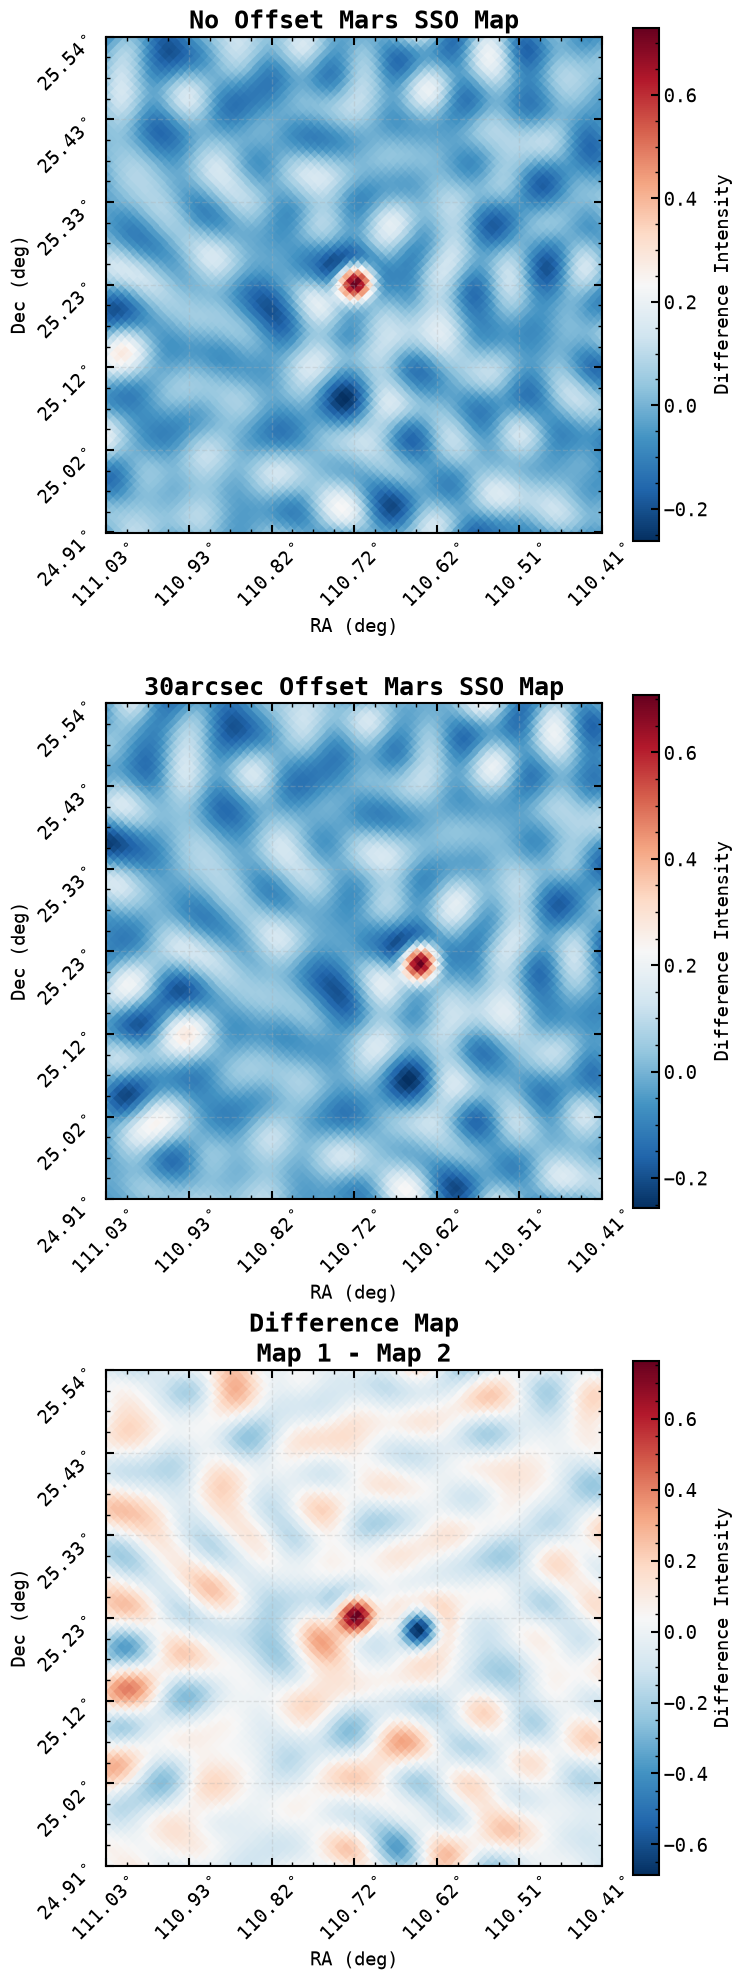

In [17]:
fig, axs = diff_plot(maps_dict["plain"]["I_map"],
          maps_dict["offset"]["I_map"],
          rot=maps_dict["plain"]["rot_est"],
          xsize=750,
          reso=0.05,
          deg=True,
          show=False,)

axs[0].set_title("No Offset Mars SSO Map")
axs[1].set_title("30arcsec Offset Mars SSO Map")
plt.savefig(os.path.join(fig_out_path, "Mars_offset_diff.png"))

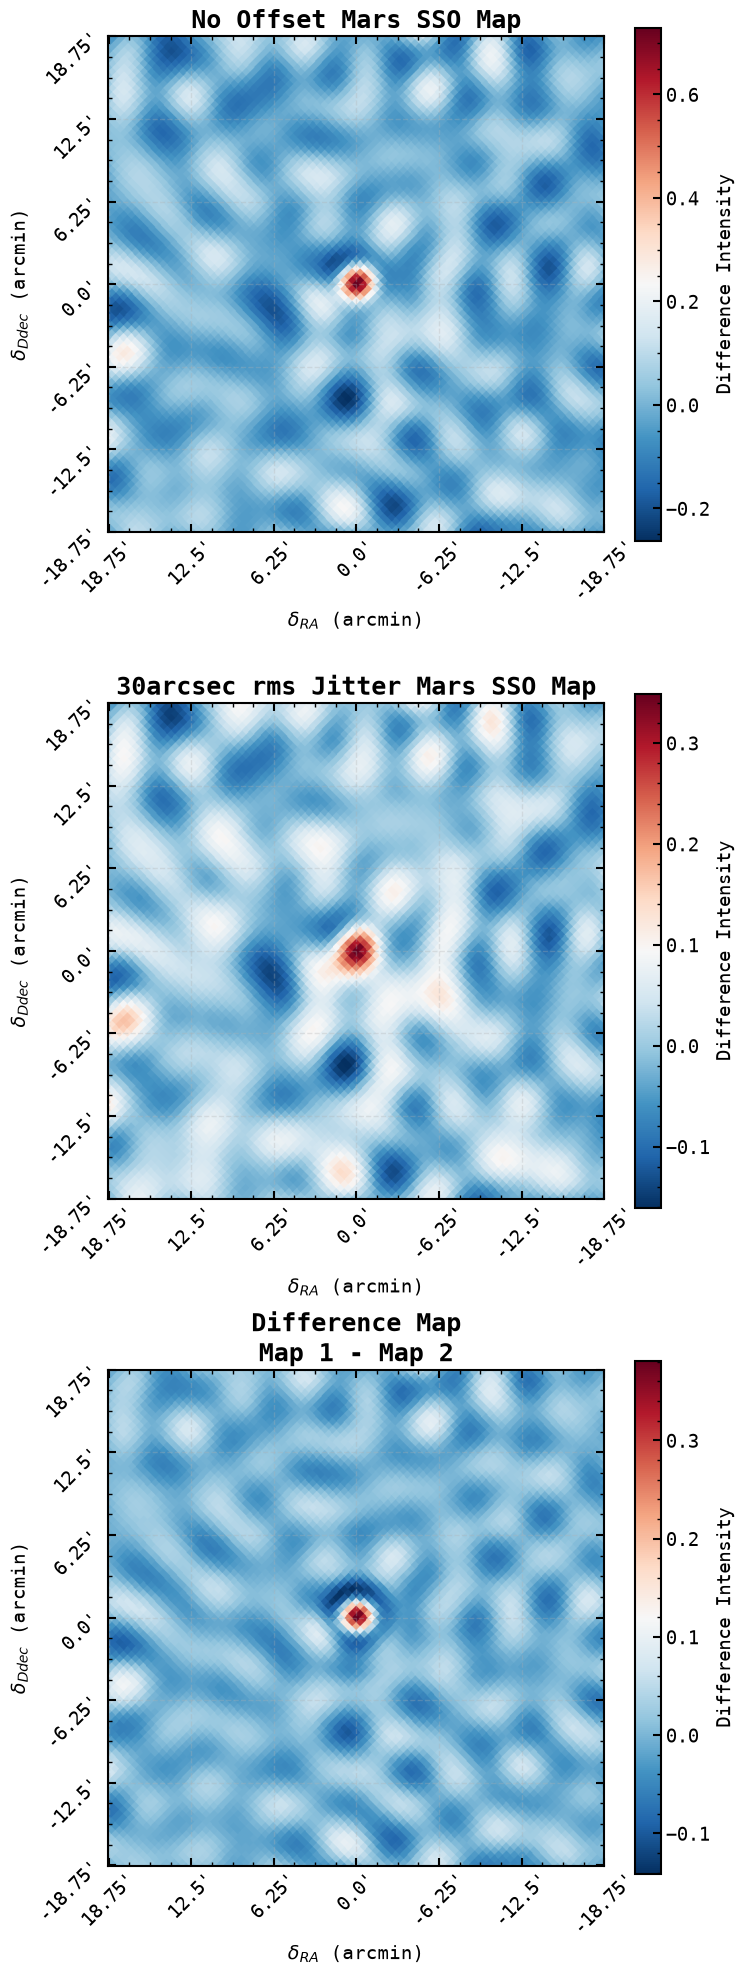

In [16]:
fig, axs = diff_plot(maps_dict["plain"]["I_map"],
          maps_dict["jitter"]["I_map"],
          rot=maps_dict["plain"]["rot_est"],
          xsize=750,
          reso=0.05,
          show=False,
          deg=False,)

axs[0].set_title("No Offset Mars SSO Map")
axs[1].set_title("30arcsec rms Jitter Mars SSO Map")
plt.savefig(os.path.join(fig_out_path, "Mars_jitter_diff.png"))